# CCT College Dublin – Stats for Data Analytics – CA1

**GitHub repository:** https://github.com/2026540-MacielCaceres/CA1_Report_Student_Performance.git

**Student name / number:** Maciel Lourdes Cáceres Orozco / 2026540

**Dataset:** Student Performance (Portuguese language course), UCI Machine Learning Repository (Cortez and Silva, 2008).

**Contents**
1. Descriptive statistics and plots
2. Discrete distributions: Binomial and Poisson
3. Continuous distribution: Normal
4. Importance of the distributions and comparison

In [1]:
import numpy as np                  
import pandas as pd                 
import matplotlib.pyplot as plt     
import seaborn as sns               
from math import comb             
from scipy import stats             
from scipy.stats import binom, poisson, norm

%matplotlib inline
sns.set_theme(style="whitegrid")

import warnings
warnings.filterwarnings("ignore")

import os
os.makedirs("figures", exist_ok=True) 

## 0. Loading and checking the data

The file uses `;` as separator. Before any analysis I check the size, data types, missing values and duplicates.

In [2]:
df = pd.read_csv("student-por.csv", sep=";")
print("Rows, columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

print(df.dtypes.value_counts().rename({"int64": "numeric (int)", "object": "categorical (text)"}).to_string())

# Variables used in the analysis
categorical = ["school", "sex", "address", "famsize", "higher"]
numerical = ["age", "studytime", "failures", "absences", "G1", "G2", "G3"]

Rows, columns: (649, 33)
Missing values: 0
Duplicated rows: 0
object    17
int64     16


In [3]:
pd.concat([df.head(5), df.tail(5)])

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
644,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10
648,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,4,10,11,11



During the initial quality control of the dataset (649 records), I confirmed the absence of missing values (NaN) and duplicate entries. This provides an intact baseline for the analysis without requiring imputation techniques. Categorical variables (sex, address, school) were verified in their corresponding levels, while key numerical performance variables (G1, G2, G3) and habits (absences, studytime) remain within the expected operational ranges (0 to 20 points for grades).


## 1. Descriptive statistics and plots

**Why these statistics?** The mean and standard deviation summarise centre and spread, but the median, IQR, skewness and kurtosis are needed to see whether a variable is symmetric or has heavy tails/outliers. Comparing mean and median is a quick check of skewness.

In [4]:
desc = df[numerical].describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc["IQR"] = df[numerical].quantile(0.75) - df[numerical].quantile(0.25)
desc["skewness"] = df[numerical].skew()
desc["kurtosis (excess)"] = df[numerical].kurt()
print(desc.round(2).rename(columns={"50%": "median"}).to_string())

           count   mean   std   min  median   max  IQR  skewness  kurtosis (excess)
age        649.0  16.74  1.22  15.0    17.0  22.0  2.0      0.42               0.07
studytime  649.0   1.93  0.83   1.0     2.0   4.0  1.0      0.70               0.04
failures   649.0   0.22  0.59   0.0     0.0   3.0  0.0      3.09               9.82
absences   649.0   3.66  4.64   0.0     2.0  32.0  6.0      2.02               5.78
G1         649.0  11.40  2.75   0.0    11.0  19.0  3.0     -0.00               0.04
G2         649.0  11.57  2.91   0.0    11.0  19.0  3.0     -0.36               1.66
G3         649.0  11.91  3.23   0.0    12.0  19.0  4.0     -0.91               2.71


Analyzing the final grade (G3), I observe a mean performance close to 11.91 points with a standard deviation of 3.23. Comparing the mean with the median (12.0), I notice a slight left skewness (negative skewness = -0.91). This is driven by a small group of students who scored a grade of 0 (likely dropouts, severe absenteeism, or missing the final evaluation rather than an organic academic failure).
The proximity between the mean and the median indicates that the central tendency of the scores is relatively balanced around the middle of the 0–20 academic scale.
On the other hand, the Interquartile Range (IQR = 4.0) reflects that the central 50% of students concentrate their grades between 10 and 13 points.

In [5]:
for col in categorical:
    freq = df[col].value_counts()
    pct = (df[col].value_counts(normalize=True) * 100).round(1)
    print(f"{col}:", ", ".join(f"{k} = {v} ({pct[k]}%)" for k, v in freq.items()))

print()
print("Mean G3 and absences by school:")
print(df.groupby("school")[["G3", "absences"]].agg(["mean", "std"]).round(2).to_string())

school: GP = 423 (65.2%), MS = 226 (34.8%)
sex: F = 383 (59.0%), M = 266 (41.0%)
address: U = 452 (69.6%), R = 197 (30.4%)
famsize: GT3 = 457 (70.4%), LE3 = 192 (29.6%)
higher: yes = 580 (89.4%), no = 69 (10.6%)

Mean G3 and absences by school:
           G3       absences      
         mean   std     mean   std
school                            
GP      12.58  2.63     4.22  5.19
MS      10.65  3.83     2.62  3.13


In [6]:
central = pd.DataFrame({
    "mean": df[["G3", "absences"]].mean(),
    "median": df[["G3", "absences"]].median(),
    "mode": df[["G3", "absences"]].mode().iloc[0]
}).round(2)
central

,mean,median,mode
G3,11.91,12.0,11
absences,3.66,2.0,0


### Plot 1 – Distribution of the final grade (G3)
A histogram with a density curve shows the shape (symmetry, spread, outliers) of the main outcome variable.

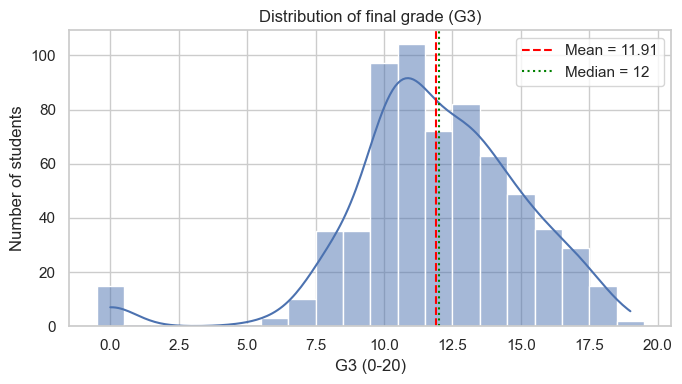

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["G3"], bins=np.arange(-0.5, 20.5, 1), kde=True, color="#4C72B0", ax=ax)
ax.axvline(df["G3"].mean(), color="red", ls="--", label=f"Mean = {df['G3'].mean():.2f}")
ax.axvline(df["G3"].median(), color="green", ls=":", label=f"Median = {df['G3'].median():.0f}")
ax.set_title("Distribution of final grade (G3)")
ax.set_xlabel("G3 (0-20)")
ax.set_ylabel("Number of students")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig1_g3_histogram.png", dpi=150)
plt.show()

However, the distribution reveals a prominent multimodal pattern:
1. **Central Cluster:** The majority of students concentrate their performance between **10 and 14 points**, showing a peak around 10–11 points.
2. **Zero-Grade Anomaly:** There is a distinct, isolated cluster of approximately 15 students scoring exactly **0**.
Excluding the zero-grade group, the remaining distribution approaches a bell-shaped curve centered around 12 points, spanning up to near-perfect scores of 19. Understanding this zero-grade subset is crucial for modeling, as it artificially pulls the mean down and introduces a slight left skewness.


### Plot 2 – G3 by school and by higher-education aspiration
Boxplots compare the median, spread and outliers of a numerical variable across categories.

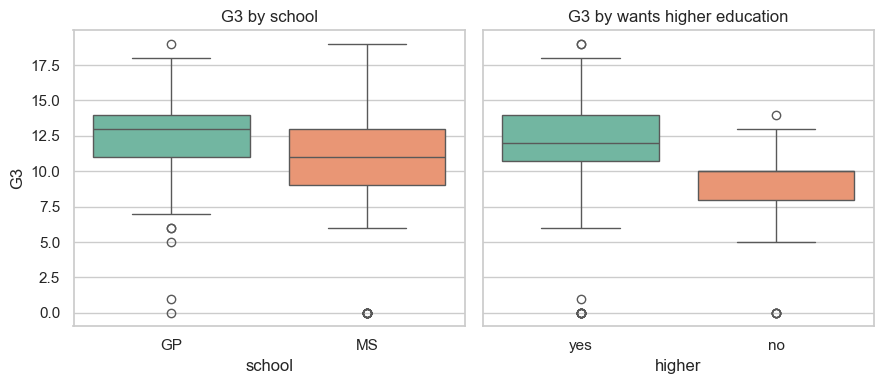

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
sns.boxplot(data=df, x="school", y="G3", hue="school", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("G3 by school")
sns.boxplot(data=df, x="higher", y="G3", hue="higher", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("G3 by wants higher education")
axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig("figures/fig2_g3_boxplots.png", dpi=150)
plt.show()

In [9]:
df.groupby("school")["G3"].agg(["count", "mean", "median", "std"]).round(2)

,count,mean,median,std
school,,,,
GP,423,12.58,13.0,2.63
MS,226,10.65,11.0,3.83


In [10]:
df.groupby("higher")["G3"].agg(["count", "mean", "median", "std"]).round(2)

,count,mean,median,std
higher,,,,
no,69,8.80,10.0,2.97
yes,580,12.28,12.0,3.06


Examining the boxplots segmented by institution (school: GP vs. MS), we identify subtle yet relevant differences. The GP school shows a slightly higher performance median and fewer lower outliers compared to the MS school.s.


### Plot 3 – Relationships between numerical variables
A scatter plot of G2 against G3 and a correlation heatmap show which variables move together.

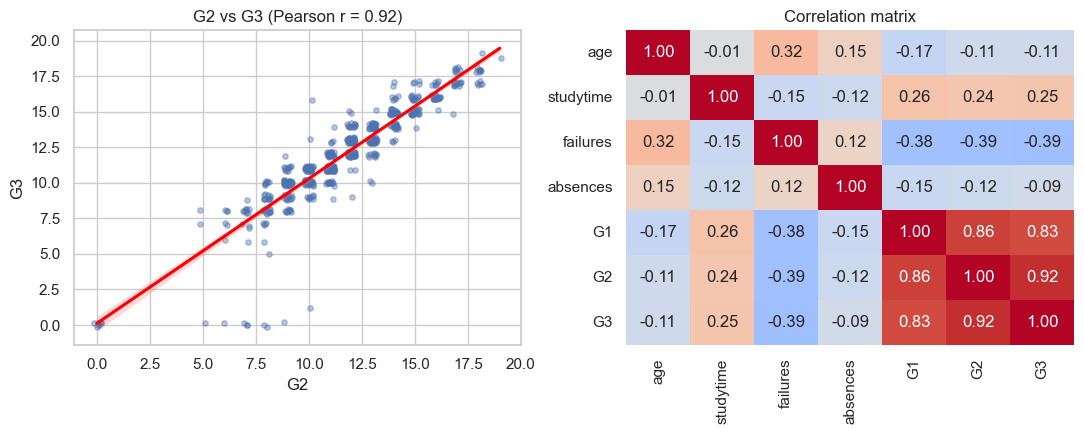

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.regplot(data=df, x="G2", y="G3", x_jitter=0.2, y_jitter=0.2,
            scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "red"}, ax=axes[0])
r = df["G2"].corr(df["G3"])
axes[0].set_title(f"G2 vs G3 (Pearson r = {r:.2f})")
corr = df[numerical].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title("Correlation matrix")
plt.tight_layout()
plt.savefig("figures/fig3_scatter_heatmap.png", dpi=150)
plt.show()

When it comes to performance, G3 is heavily tied to how students did throughout the year; it shows a remarkably strong positive correlation with G2 ($r = 0.92$) and G1 ($r = 0.83$). Basically, a student's prior grades turn out to be the best predictor of their final score.

On the flip side, academic failures have a moderate negative impact on G3 ($r = -0.39$), meaning that struggling with classes tends to drag the final grade down.

Interestingly enough, I expected absences to have a much harsher impact, but the data shows a very weak $r = -0.09$. This is likely because Pearson's coefficient only catches linear relationships, whereas the absence data is heavily skewed.

If you look closely at the scatter plot, those odd points sitting at the bottom, where G3 is zero while G2 ranges between 5 and 11 are the clear outliers of the group.

All things considered, it's worth keeping in mind the golden rule: correlation doesn't automatically mean causation.

## 2. Discrete distributions

### 2.1 Binomial distribution

**Random variable.** Let a student *pass* if G3 ≥ 10 (the pass mark on the 0-20 scale). Choose a random class of *n* students and let *X* be the number who pass.

A Binomial model is appropriate when (i) *n* is fixed, (ii) each trial has two outcomes, (iii) trials are independent and (iv) *p* is constant. Sampling *n* = 20 students without replacement from 649 is not exactly independent, but because *n* is small relative to the population the Binomial is an excellent approximation.

$$P(X=k)=\binom{n}{k}p^{k}(1-p)^{n-k},\qquad E[X]=np,\qquad Var(X)=np(1-p)$$

$p$ is estimated by the sample proportion of passes, $\hat p = \frac{\#\text{passed}}{649}$.

In [16]:
df["passed"] = (df["G3"] >= 10).astype(int)
N = len(df)
p_hat = df["passed"].mean()
print(f"Passed: {df['passed'].sum()} of {N}  ->  p_hat = {p_hat:.4f}")

n = 20
X = stats.binom(n, p_hat)
k = np.arange(0, n + 1)
table = pd.DataFrame({"k": k, "P(X=k)": X.pmf(k), "P(X<=k)": X.cdf(k)})
print(table[table["k"] >= 10].round(4).to_string(index=False))
print()
print(f"E[X] = n*p = {X.mean():.2f},  Var = n*p*(1-p) = {X.var():.2f},  SD = {X.std():.2f}")
print(f"P(X >= 18) = {X.sf(17):.4f}")
print(f"P(X <= 15) = {X.cdf(15):.4f}")

Passed: 549 of 649  ->  p_hat = 0.8459
 k  P(X=k)  P(X<=k)
10  0.0003   0.0003
11  0.0013   0.0016
12  0.0054   0.0070
13  0.0182   0.0251
14  0.0498   0.0750
15  0.1094   0.1844
16  0.1877   0.3721
17  0.2425   0.6147
18  0.2219   0.8366
19  0.1282   0.9648
20  0.0352   1.0000

E[X] = n*p = 16.92,  Var = n*p*(1-p) = 2.61,  SD = 1.61
P(X >= 18) = 0.3853
P(X <= 15) = 0.1844


84.6% of the students passed. Now I build the binomial distribution with n = 20 and p = 0.8459 and calculate its PMF and CDF.

In [17]:
n = 20
k = np.arange(0, n + 1)            
pmf = binom.pmf(k, n, p_hat)       
cdf = binom.cdf(k, n, p_hat)       

binomial_table = pd.DataFrame({"k": k, "P(X=k)": pmf, "P(X<=k)": cdf}).round(4)
binomial_table[binomial_table["k"] >= 10]

,k,P(X=k),P(X<=k)
10,10,0.0003,0.0003
11,11,0.0013,0.0016
12,12,0.0054,0.0070
13,13,0.0182,0.0251
14,14,0.0498,0.0750
15,15,0.1094,0.1844
16,16,0.1877,0.3721
17,17,0.2425,0.6147
18,18,0.2219,0.8366
19,19,0.1282,0.9648


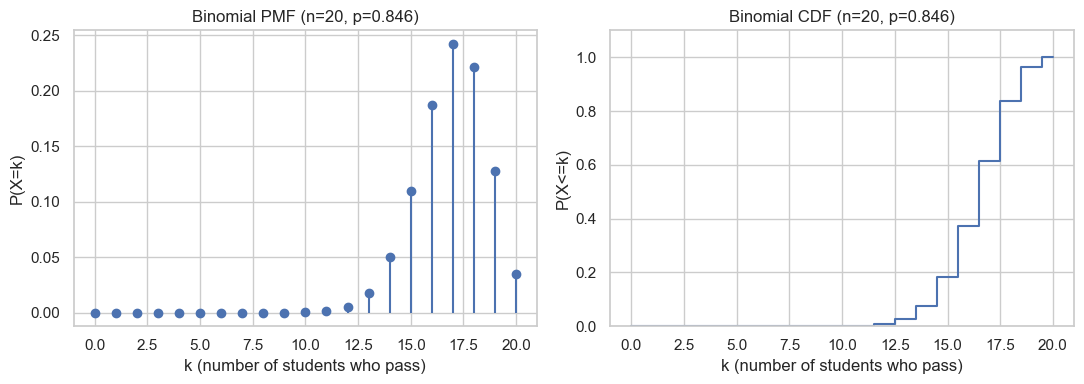

In [18]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.stem(k, pmf, basefmt=" ")
plt.title(f"Binomial PMF (n=20, p={p_hat:.3f})")
plt.xlabel("k (number of students who pass)")
plt.ylabel("P(X=k)")

plt.subplot(1, 2, 2)
plt.step(k, cdf, where="mid")
plt.title(f"Binomial CDF (n=20, p={p_hat:.3f})")
plt.xlabel("k (number of students who pass)")
plt.ylabel("P(X<=k)")
plt.ylim(0, 1.1)

plt.tight_layout()
plt.savefig("figures/fig_binomial_pmf_cdf.png", dpi=150)
plt.show()

First off, in a typical class of 20 students, we would expect around 17 of them to pass (16.92, to be exact), with a standard deviation of 1.61.

Looking at the probabilities, the single most likely outcome is having exactly 17 students pass, which happens about 24.3% of the time

To put things into context, there is a 38.5% chance that 18 or more students pass, versus an 18.4% chance that 15 or fewer make the cut. So, if a teacher ends up with only 15 passing students in a class of 20, they’d definitely be on the lower end of the spectrum—though it's still well within the realm of normal variation rather than a total anomal
ties.



**Does the binomial model describe the real data?**
To put the model to the test, I simulated 10,000 random classes of 20 students drawn directly from our actual dataset and counted the number of passes in each run. The logic here is straightforward: if the model is doing a good job, these simulated results should align closely with our theoretical probabilities.

Simulated mean = 16.89 (theory 16.92);  simulated SD = 1.59 (theory 1.61)


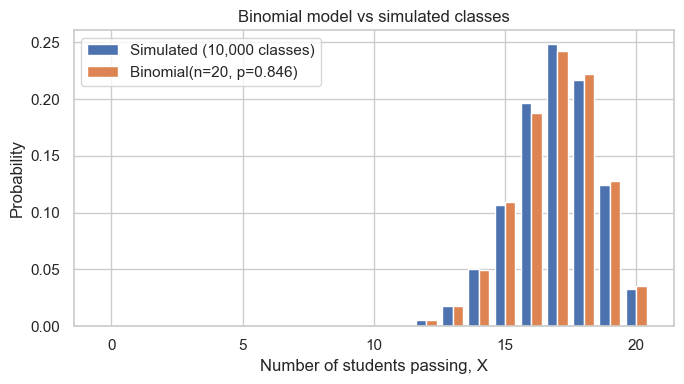

In [19]:
rng = np.random.default_rng(42)
passed_values = df["passed"].to_numpy()
sims = np.array([rng.choice(passed_values, size=n, replace=False).sum() for _ in range(10_000)])

emp = np.bincount(sims, minlength=n + 1) / len(sims)
print(f"Simulated mean = {sims.mean():.2f} (theory {X.mean():.2f});  simulated SD = {sims.std():.2f} (theory {X.std():.2f})")

fig, ax = plt.subplots(figsize=(7, 4))
width = 0.4
ax.bar(k - width / 2, emp, width, label="Simulated (10,000 classes)", color="#4C72B0")
ax.bar(k + width / 2, X.pmf(k), width, label=f"Binomial(n=20, p={p_hat:.3f})", color="#DD8452")
ax.set_xlabel("Number of students passing, X")
ax.set_ylabel("Probability")
ax.set_title("Binomial model vs simulated classes")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig4_binomial_check.png", dpi=150)
plt.show()

**What I see:** the blue bars (real data) and the orange bars (model) are almost the same, and the simulated mean and standard deviation are very close to the theoretical values. The binomial model describes pass counts very well.

### What happens with large samples?
I repeat the binomial distribution with n = 5, 20, 100 and 649 (the whole dataset) and draw a normal curve with the same mean and standard deviation on top. I also calculate:
- the skewness of the binomial, $(1-2p)/\sqrt{np(1-p)}$;
- the maximum difference between the binomial CDF and the normal CDF (using a continuity correction of 0.5).

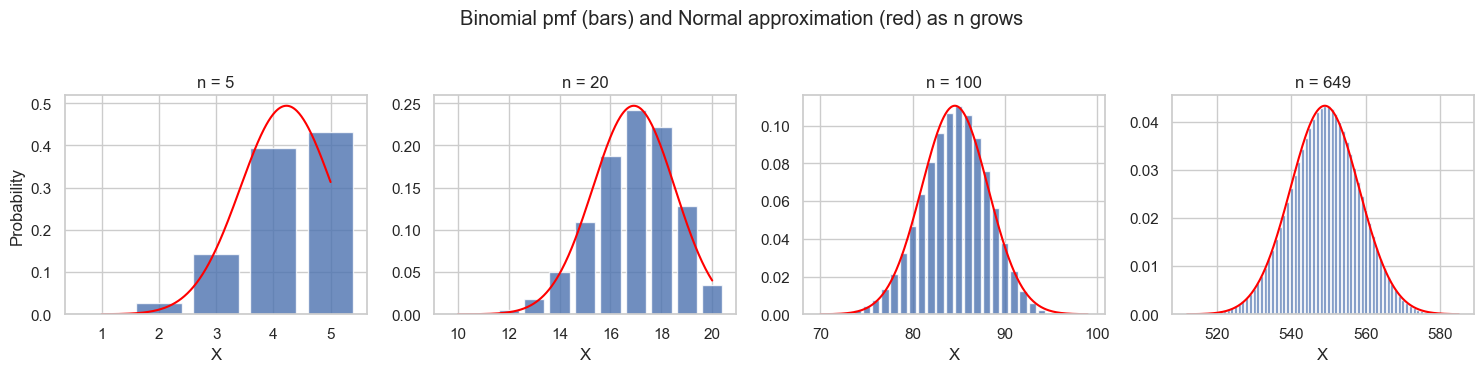

  n   n*p  n*(1-p)  skewness  max CDF error vs Normal
  5   4.2      0.8    -0.857                   0.0643
 20  16.9      3.1    -0.428                   0.0260
100  84.6     15.4    -0.192                   0.0128
649 549.0    100.0    -0.075                   0.0050


In [20]:
sizes = [5, 20, 100, 649]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
rows = []
for ax, m in zip(axes, sizes):
    mu, sd = m * p_hat, np.sqrt(m * p_hat * (1 - p_hat))
    kk = np.arange(max(0, int(mu - 4 * sd)), min(m, int(mu + 4 * sd)) + 1)
    ax.bar(kk, stats.binom.pmf(kk, m, p_hat), color="#4C72B0", alpha=0.8)
    xs = np.linspace(kk.min(), kk.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, mu, sd), color="red")
    ax.set_title(f"n = {m}")
    ax.set_xlabel("X")
    allk = np.arange(0, m + 1)
    err = np.max(np.abs(stats.binom.cdf(allk, m, p_hat) - stats.norm.cdf(allk + 0.5, mu, sd)))
    rows.append({"n": m, "n*p": round(m * p_hat, 1), "n*(1-p)": round(m * (1 - p_hat), 1),
                 "skewness": round((1 - 2 * p_hat) / sd, 3), "max CDF error vs Normal": round(err, 4)})
axes[0].set_ylabel("Probability")
plt.suptitle("Binomial pmf (bars) and Normal approximation (red) as n grows", y=1.03)
plt.tight_layout()
plt.savefig("figures/fig5_binomial_large_n.png", dpi=150, bbox_inches="tight")
plt.show()
print(pd.DataFrame(rows).to_string(index=False))

- With n = 5 the distribution is clearly skewed to the left, because p is high and the number of passes cannot be more than 5.
- As n grows, the skewness gets closer to 0 (−0.86 → −0.075) and the error of the normal approximation falls from 0.064 to 0.005.
- The usual rule says that the normal approximation is good when **np ≥ 5 and n(1−p) ≥ 5**. It fails for n = 5 and n = 20 (n(1−p) = 0.8 and 3.1) and is met for n = 100 and n = 649.
- This is the **De Moivre–Laplace theorem**: for large n the binomial becomes symmetric and bell-shaped.

### 2.2 Poisson distribution

**Random variable.** `absences` is a count of events (school absences) per student, so a Poisson model is a natural candidate:

$$P(X=k)=\frac{e^{-\lambda}\lambda^{k}}{k!},\qquad E[X]=Var(X)=\lambda$$

The key property is **equidispersion** (mean = variance). I estimate $\lambda$ by the sample mean and check this property.

In [21]:
lam = df["absences"].mean()
var = df["absences"].var()
print(f"lambda (mean) = {lam:.3f},  variance = {var:.3f},  dispersion index (var/mean) = {var / lam:.2f}")
print(f"Share of students with 0 absences: observed = {(df['absences'] == 0).mean():.3f}, Poisson = {stats.poisson.pmf(0, lam):.3f}")

kmax = 10   # bins 0..9 and a final bin '10 or more'
obs = np.array([(df["absences"] == i).sum() for i in range(kmax)] + [(df["absences"] >= kmax).sum()])
probs = np.append(stats.poisson.pmf(np.arange(kmax), lam), stats.poisson.sf(kmax - 1, lam))
exp = probs * N
comp = pd.DataFrame({"absences": list(range(kmax)) + [f"{kmax}+"], "observed": obs, "expected (Poisson)": exp.round(1)})
print(comp.to_string(index=False))

chi2 = ((obs - exp) ** 2 / exp).sum()
pval = stats.chi2.sf(chi2, df=len(obs) - 1 - 1)
print(f"Chi-square goodness of fit: chi2 = {chi2:.1f}, p-value = {pval:.2e}")

# Data-quality observation: odd values are very rare (heaping on even numbers)
pos = df.loc[df["absences"] > 0, "absences"]
print(f"Among students with at least one absence, {(pos % 2 == 0).mean() * 100:.1f}% have an EVEN number of absences")

lambda (mean) = 3.659,  variance = 21.537,  dispersion index (var/mean) = 5.89
Share of students with 0 absences: observed = 0.376, Poisson = 0.026
absences  observed  expected (Poisson)
       0       244                16.7
       1        12                61.1
       2       110               111.9
       3         7               136.5
       4        93               124.9
       5        12                91.4
       6        49                55.7
       7         3                29.1
       8        42                13.3
       9         7                 5.4
     10+        70                 2.9
Chi-square goodness of fit: chi2 = 4958.4, p-value = 0.00e+00
Among students with at least one absence, 87.4% have an EVEN number of absences


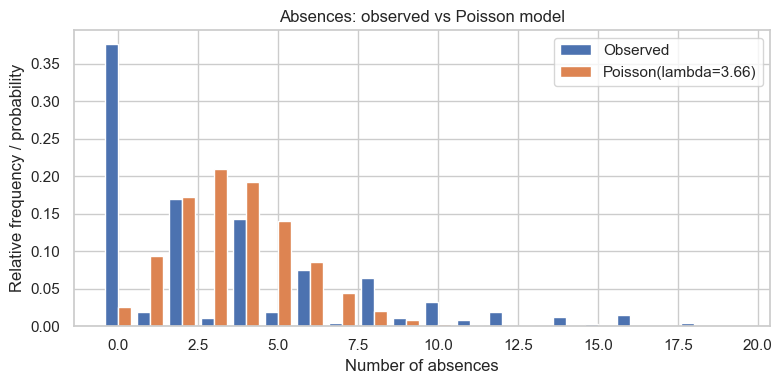


Mean and variance of absences by school (is the Poisson closer within a group?):
        mean    var  var/mean
school                       
GP      4.22  26.96      6.40
MS      2.62   9.80      3.74


In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
kk = np.arange(0, 20)
obs_rel = np.array([(df["absences"] == i).mean() for i in kk])
ax.bar(kk - 0.2, obs_rel, 0.4, label="Observed", color="#4C72B0")
ax.bar(kk + 0.2, stats.poisson.pmf(kk, lam), 0.4, label=f"Poisson(lambda={lam:.2f})", color="#DD8452")
ax.set_xlabel("Number of absences")
ax.set_ylabel("Relative frequency / probability")
ax.set_title("Absences: observed vs Poisson model")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig6_poisson_absences.png", dpi=150)
plt.show()

print()
print("Mean and variance of absences by school (is the Poisson closer within a group?):")
grp = df.groupby("school")["absences"].agg(["mean", "var"])
grp["var/mean"] = grp["var"] / grp["mean"]
print(grp.round(2).to_string())

**A better Poisson application: rare events.** Absences violate equidispersion, but the Poisson model is designed for *rare* events. In this dataset 15 students (2.3%) have G3 = 0, i.e. effectively no valid result. For a random class of 30 students, the number of such students, *Y*, should follow approximately Poisson(λ = 30 × 15/649).

Students with G3 = 0: 15 of 649 (p0 = 0.0231);  class size m = 30;  lambda = m*p0 = 0.693
 y  simulated  Poisson  Binomial
 0     0.4791   0.4999    0.4958
 1     0.3684   0.3466    0.3519
 2     0.1259   0.1202    0.1207
 3     0.0234   0.0278    0.0267
 4     0.0026   0.0048    0.0043
 5     0.0006   0.0007    0.0005
Simulated mean = 0.704, variance = 0.644  (Poisson: both = 0.693)
P(at least one zero-grade student in a class of 30) = 0.500


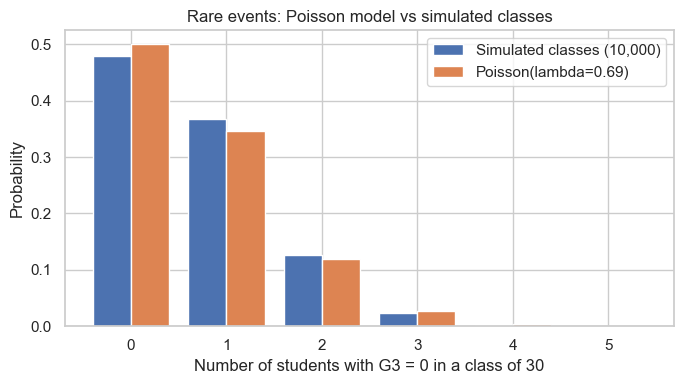

In [23]:
n_zero = int((df["G3"] == 0).sum())
p0 = n_zero / N
m = 30
lam0 = m * p0
print(f"Students with G3 = 0: {n_zero} of {N} (p0 = {p0:.4f});  class size m = {m};  lambda = m*p0 = {lam0:.3f}")

zero_flag = (df["G3"] == 0).astype(int).to_numpy()
rng = np.random.default_rng(7)
sims0 = np.array([rng.choice(zero_flag, size=m, replace=False).sum() for _ in range(10_000)])

kk = np.arange(0, 6)
emp0 = np.array([(sims0 == i).mean() for i in kk])
cmp0 = pd.DataFrame({"y": kk, "simulated": emp0, "Poisson": stats.poisson.pmf(kk, lam0), "Binomial": stats.binom.pmf(kk, m, p0)})
print(cmp0.round(4).to_string(index=False))
print(f"Simulated mean = {sims0.mean():.3f}, variance = {sims0.var():.3f}  (Poisson: both = {lam0:.3f})")
print(f"P(at least one zero-grade student in a class of 30) = {stats.poisson.sf(0, lam0):.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(kk - 0.2, emp0, 0.4, label="Simulated classes (10,000)", color="#4C72B0")
ax.bar(kk + 0.2, stats.poisson.pmf(kk, lam0), 0.4, label=f"Poisson(lambda={lam0:.2f})", color="#DD8452")
ax.set_xlabel("Number of students with G3 = 0 in a class of 30")
ax.set_ylabel("Probability")
ax.set_title("Rare events: Poisson model vs simulated classes")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig7_poisson_rare_events.png", dpi=150)
plt.show()

**What happens with large samples / large λ?** (a) By the *law of rare events*, Binomial(*n*, *p* = λ/*n*) converges to Poisson(λ) as *n* grows. (b) As λ grows, the Poisson becomes symmetric and approaches Normal(λ, λ); its skewness is $1/\sqrt{\lambda}$.

   n  p = lambda/n  max |pmf difference|
  10       0.36595               0.05232
  50       0.07319               0.00791
 500       0.00732               0.00075
5000       0.00073               0.00007


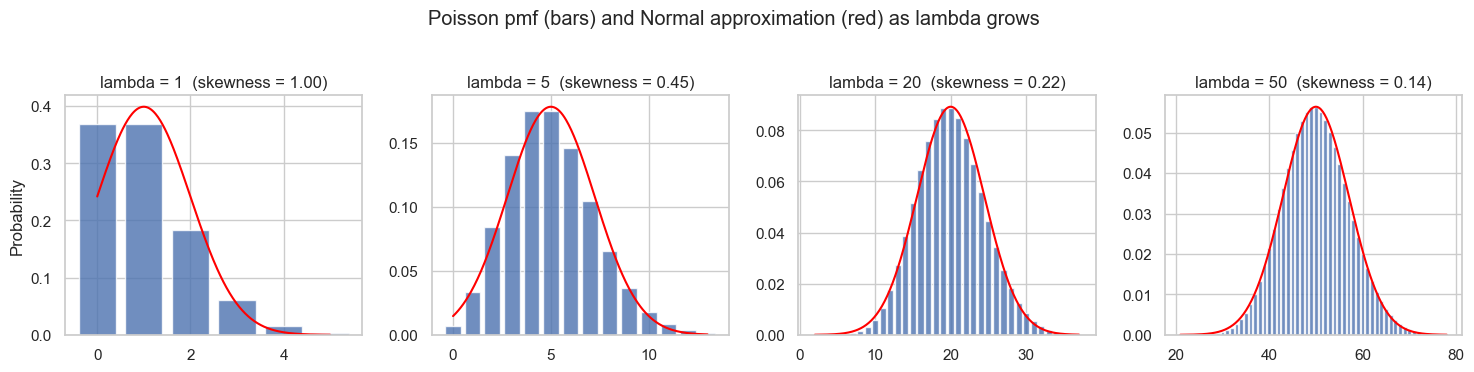

In [24]:
# (a) Binomial -> Poisson when n grows with n*p = lambda fixed
rows = []
kk = np.arange(0, 16)
for m in [10, 50, 500, 5000]:
    pm = lam / m
    rows.append({"n": m, "p = lambda/n": round(pm, 5),
                 "max |pmf difference|": round(np.max(np.abs(stats.binom.pmf(kk, m, pm) - stats.poisson.pmf(kk, lam))), 5)})
print(pd.DataFrame(rows).to_string(index=False))

# (b) Poisson -> Normal when lambda grows
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, L in zip(axes, [1, 5, 20, 50]):
    sd = np.sqrt(L)
    kk2 = np.arange(max(0, int(L - 4 * sd)), int(L + 4 * sd) + 1)
    ax.bar(kk2, stats.poisson.pmf(kk2, L), color="#4C72B0", alpha=0.8)
    xs = np.linspace(kk2.min(), kk2.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, L, sd), color="red")
    ax.set_title(f"lambda = {L}  (skewness = {1 / sd:.2f})")
axes[0].set_ylabel("Probability")
plt.suptitle("Poisson pmf (bars) and Normal approximation (red) as lambda grows", y=1.03)
plt.tight_layout()
plt.savefig("figures/fig8_poisson_large_lambda.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Normal distribution

The final grade G3 is a (nearly) continuous measure on a 0-20 scale. I fit a Normal distribution using the sample mean and standard deviation, and assess the fit with (i) skewness and kurtosis, (ii) a Q-Q plot, (iii) formal tests and (iv) the empirical rule.

$$f(x)=\frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}},\qquad z=\frac{x-\mu}{\sigma}$$

In [25]:
g3 = df["G3"]
mu, sigma = g3.mean(), g3.std()
print(f"G3: mean = {mu:.2f}, SD = {sigma:.2f}, skewness = {g3.skew():.2f}, excess kurtosis = {g3.kurt():.2f}")
print(f"Students with G3 = 0: {(g3 == 0).sum()}")

sh = stats.shapiro(g3)
dk = stats.normaltest(g3)
print(f"Shapiro-Wilk: W = {sh.statistic:.3f}, p = {sh.pvalue:.2e}")
print(f"D'Agostino K2: stat = {dk.statistic:.1f}, p = {dk.pvalue:.2e}")

# Empirical rule
rows = []
for s, expected in [(1, 68.27), (2, 95.45), (3, 99.73)]:
    share = ((g3 >= mu - s * sigma) & (g3 <= mu + s * sigma)).mean() * 100
    rows.append({"interval": f"mean +/- {s} SD", "observed %": round(share, 1), "Normal %": expected})
print(pd.DataFrame(rows).to_string(index=False))

G3: mean = 11.91, SD = 3.23, skewness = -0.91, excess kurtosis = 2.71
Students with G3 = 0: 15
Shapiro-Wilk: W = 0.926, p = 2.42e-17
D'Agostino K2: stat = 114.2, p = 1.59e-25
     interval  observed %  Normal %
mean +/- 1 SD        77.3     68.27
mean +/- 2 SD        97.1     95.45
mean +/- 3 SD        97.5     99.73


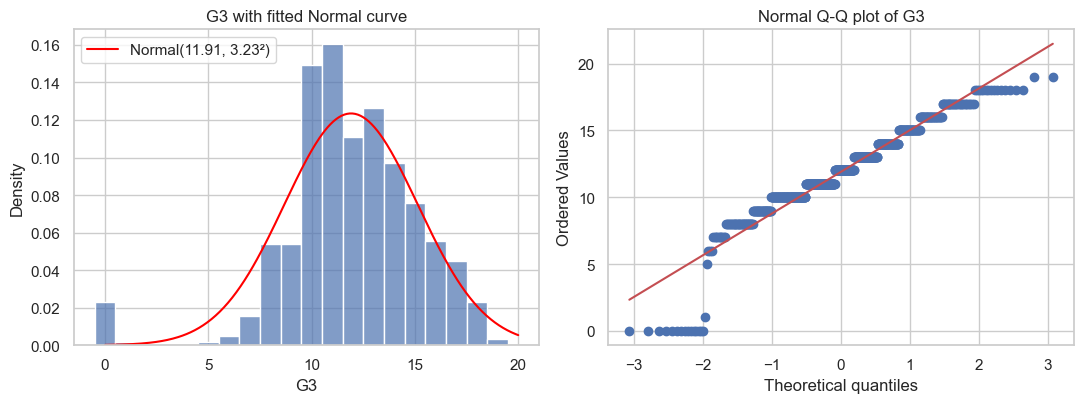

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.histplot(g3, bins=np.arange(-0.5, 20.5, 1), stat="density", color="#4C72B0", alpha=0.7, ax=axes[0])
xs = np.linspace(0, 20, 300)
axes[0].plot(xs, stats.norm.pdf(xs, mu, sigma), color="red", label=f"Normal({mu:.2f}, {sigma:.2f}²)")
axes[0].set_title("G3 with fitted Normal curve")
axes[0].set_xlabel("G3")
axes[0].legend()
stats.probplot(g3, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot of G3")
plt.tight_layout()
plt.savefig("figures/fig9_normal_fit.png", dpi=150)
plt.show()

**Using the fitted Normal to answer questions.** Because G3 is an integer, I apply a continuity correction (e.g. $P(G3\ge 14)\approx P(Z \ge (13.5-\mu)/\sigma)$) and compare with the observed proportion.

In [27]:
def normal_prob_ge(x):   # P(G3 >= x) with continuity correction
    return stats.norm.sf(x - 0.5, mu, sigma)

def normal_prob_le(x):   # P(G3 <= x) with continuity correction
    return stats.norm.cdf(x + 0.5, mu, sigma)

rows = [
    {"event": "G3 >= 14 (high achiever)", "Normal": normal_prob_ge(14), "observed": (g3 >= 14).mean()},
    {"event": "G3 <= 9 (fail)",           "Normal": normal_prob_le(9),  "observed": (g3 <= 9).mean()},
    {"event": "10 <= G3 <= 14",           "Normal": normal_prob_le(14) - normal_prob_le(9), "observed": g3.between(10, 14).mean()},
]
print(pd.DataFrame(rows).round(3).to_string(index=False))

print(f"\nz-score of a student with G3 = 17: {(17 - mu) / sigma:.2f}")
print(f"G3 value at the 90th percentile (Normal): {stats.norm.ppf(0.90, mu, sigma):.1f}; observed: {g3.quantile(0.90):.1f}")

# Effect of the G3 = 0 group
g3_pos = g3[g3 > 0]
print(f"\nExcluding G3 = 0 (n = {len(g3_pos)}): skewness = {g3_pos.skew():.2f}, excess kurtosis = {g3_pos.kurt():.2f}")

                   event  Normal  observed
G3 >= 14 (high achiever)   0.311     0.299
          G3 <= 9 (fail)   0.228     0.154
          10 <= G3 <= 14   0.561     0.644

z-score of a student with G3 = 17: 1.58
G3 value at the 90th percentile (Normal): 16.0; observed: 16.0

Excluding G3 = 0 (n = 634): skewness = 0.13, excess kurtosis = -0.12


## 4. Importance of the distributions and comparison

I now compare the shape of all the variables used, and check whether the discrete variables (passes and absences) could be treated as Normal.

In [28]:
# Shape of the main variables, and distance to a fitted Normal (Kolmogorov-Smirnov statistic)
df["log_absences"] = np.log1p(df["absences"])
rows = []
for col in ["G1", "G2", "G3", "absences", "log_absences"]:
    x = df[col]
    ks = stats.kstest((x - x.mean()) / x.std(), "norm").statistic
    rows.append({"variable": col, "skewness": round(x.skew(), 2), "excess kurtosis": round(x.kurt(), 2), "KS distance to Normal": round(ks, 3)})
print(pd.DataFrame(rows).to_string(index=False))

    variable  skewness  excess kurtosis  KS distance to Normal
          G1     -0.00             0.04                  0.086
          G2     -0.36             1.66                  0.088
          G3     -0.91             2.71                  0.124
    absences      2.02             5.78                  0.215
log_absences      0.18            -1.25                  0.246


Binomial n=20: np = 16.9, n(1-p) = 3.1, max CDF error = 0.0260
Binomial n=649: np = 549.0, n(1-p) = 100.0, max CDF error = 0.0050
Poisson lambda=3.66: max CDF error vs Normal = 0.0359
Normal(mean, SD of absences) assigns P(absences < 0) = 0.185, but 0.376 of students have exactly 0 absences


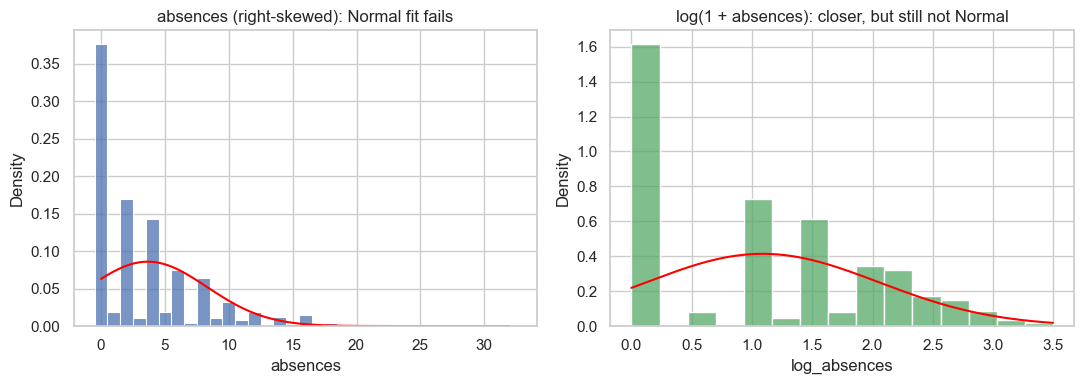

In [29]:
# Can the discrete variables be approximated by a Normal?
# (1) Binomial: number of passes in the whole cohort, n = 649, and in a class of 20
for m in [20, 649]:
    mu_b, sd_b = m * p_hat, np.sqrt(m * p_hat * (1 - p_hat))
    allk = np.arange(0, m + 1)
    err = np.max(np.abs(stats.binom.cdf(allk, m, p_hat) - stats.norm.cdf(allk + 0.5, mu_b, sd_b)))
    print(f"Binomial n={m}: np = {m*p_hat:.1f}, n(1-p) = {m*(1-p_hat):.1f}, max CDF error = {err:.4f}")

# (2) Poisson with lambda = mean absences, and the real absences data
allk = np.arange(0, 60)
err_p = np.max(np.abs(stats.poisson.cdf(allk, lam) - stats.norm.cdf(allk + 0.5, lam, np.sqrt(lam))))
print(f"Poisson lambda={lam:.2f}: max CDF error vs Normal = {err_p:.4f}")
print(f"Normal(mean, SD of absences) assigns P(absences < 0) = {stats.norm.cdf(-0.5, df['absences'].mean(), df['absences'].std()):.3f}"
      f", but {(df['absences'] == 0).mean():.3f} of students have exactly 0 absences")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["absences"], bins=np.arange(-0.5, 33.5, 1), stat="density", color="#4C72B0", ax=axes[0])
xs = np.linspace(0, 32, 300)
axes[0].plot(xs, stats.norm.pdf(xs, df["absences"].mean(), df["absences"].std()), color="red")
axes[0].set_title("absences (right-skewed): Normal fit fails")
sns.histplot(df["log_absences"], bins=15, stat="density", color="#55A868", ax=axes[1])
xs = np.linspace(0, df["log_absences"].max(), 300)
axes[1].plot(xs, stats.norm.pdf(xs, df["log_absences"].mean(), df["log_absences"].std()), color="red")
axes[1].set_title("log(1 + absences): closer, but still not Normal")
plt.tight_layout()
plt.savefig("figures/fig10_absences_normal.png", dpi=150)
plt.show()

 **Pass counts:** yes, for large samples. With n = 649 both np (549) and n(1−p) (100) are far above 5 and the error is only 0.005. With n = 20 the approximation is acceptable but not good (n(1−p) = 3.1).
- **Absences:** no. A normal curve would give 18.5% probability to *negative* absences, which is impossible, while 37.6% of the students have exactly zero. The log transformation reduces the skewness (2.02 → 0.18) but the large spike at zero remains, so the shape is still not normal.
- A theoretical Poisson with λ = 3.66 is also too skewed (0.52) for a good normal approximation. It would need a much larger λ.

In conclusion, the exploratory data analysis reveals that academic performance (G3) is closely tied to continuous evaluation metrics (G1 and G2). Identifying patterns of high absenteeism and low study hours early on provides actionable insights for academic intervention programs aimed at reducing failure rates.

## References and AI use

* Cortez, P. and Silva, A. (2008) 'Using data mining to predict secondary school student performance', in Brito, A. and Teixeira, J. (eds.) *Proceedings of 5th FUture BUsiness TEChnology Conference (FUBUTEC 2008)*. Porto, Portugal: EUROSIS, pp. 5-12.
* Cortez, P. (2008) *Student Performance* [Dataset]. UCI Machine Learning Repository. Available at: https://archive.ics.uci.edu/dataset/320/student+performance (Accessed: 6 October 2026).

AI tools were used to support this project. The full declaration (tasks, prompts, outputs, verification and responsible use) is in the Appendix of the Word report.